### 1. Install NEURON and Download the BBP Model
We will install NEURON, clone the classic BBP L5PC model from ModelDB (Hay et al. 2011), and compile the `.mod` mechanisms.

In [1]:
#@title NEURON install (launch only once) and git-clone a BBP model
# Note: Google Colab gives you access to an "instance".
# This is a virtual machine ("container" would be more correct) that runs
# Linux with already a Python installation.
!pip install neuron plotly ipywidgets matplotlib

# Install the LFPy library
!pip install LFPy

# Clone the Hay 2011 BBP L5PC model
!git clone https://github.com/ModelDBRepository/139653.git bbp_l5pc

# Compile the mechanisms (mod files)
!cd bbp_l5pc && nrnivmodl mod

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 61.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 89.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [neuron]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 931.6/931.6 kB 11.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [LFPy]
Cloning into 'bbp_l5pc'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (22/22), done.
remote: Compressing objects: 100% (21/21), done.
remote: Total 81 (delta 5), reused 7 (delta 1), pack-reused 59 (from 1)
Receiving objects: 100% (81/81), 652.07 KiB | 3.43 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/bbp_l5pc
cfiles =
Mod files: "mod/CaDynamics_E2.mod" "mod/Ca_HVA.mod" "mod/Ca_LVAst.mod" "mod/epsp.mod" "mod/Ih.mod" "mod/Im.mod" "mod/K_Pst.mod" "mod/K_Tst.mod" "mod/Nap_Et2.mod" "mod/NaTa_t.mod" "mod/NaTs2_t.mod" "mod/SK_E2.mod" "mod/SKv3_1.mod"

Creating 'x86_64' directory for .o files.

MODOBJS= ./CaDynamics_E2

### 2. Load the Model into NEURON
We load the standard HOC templates and initialize the morphology.

In [2]:
#@title Load HOC templates and morphology
import os
from neuron import h, gui

# Change to the model directory so NEURON can find local files
if os.path.basename(os.getcwd()) != 'bbp_l5pc':
    os.chdir('bbp_l5pc')

# Load standard run and 3D import libraries
h.load_file('stdrun.hoc')
h.load_file('import3d.hoc')

# Load compiled mechanisms only if not already loaded to prevent errors
if not hasattr(h, 'CaDynamics_E2'):
    h.nrn_load_dll('x86_64/libnrnmech.so')

# Load BBP templates
h.load_file('models/L5PCbiophys3.hoc')
h.load_file('models/L5PCtemplate.hoc')

# Instantiate the cell with the provided morphology
cell = h.L5PCtemplate('morphologies/cell1.asc')
print("Model loaded successfully!")


Model loaded successfully!


### 3. Display 3D Morphology
Using NEURON's built-in Plotly support, we can visualize the intricate morphology of the pyramidal cell.

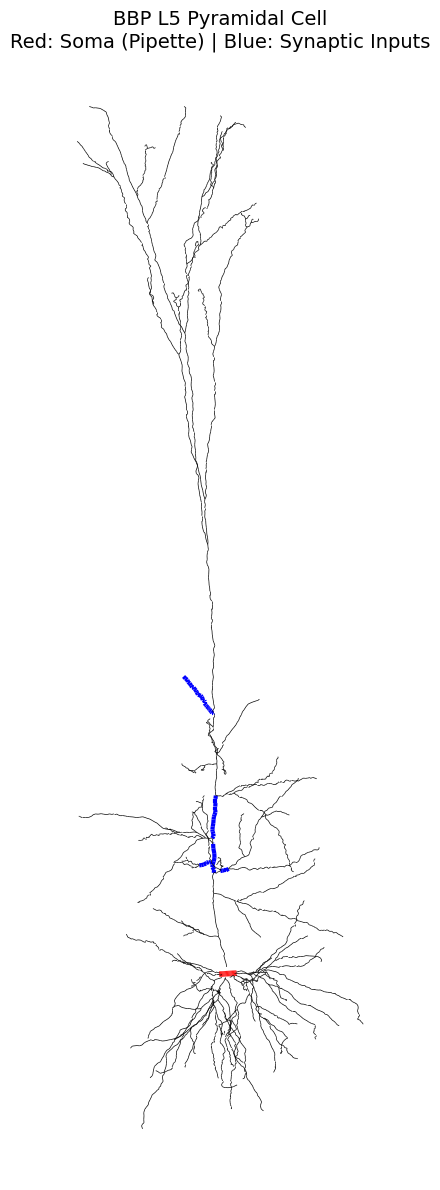

In [3]:
#@title Plot the morphology of the (BBP) model for a rat cortical L5 pyramidal neuron
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import random

# Pre-select 5 apical dendrites for the forthcoming synaptic inputs
random.seed(42)
target_dends = [cell.apic[random.randint(0, len(cell.apic)-1)] for _ in range(5)]

# Set up the Matplotlib figure
fig, ax = plt.subplots(figsize=(8, 12))
lines = []
colors = []
linewidths = []

# Extract 2D coordinates directly for perfect alignment and control
for sec in h.allsec():
    is_soma = 'soma' in sec.name()
    is_target = sec in target_dends

    # Style: Soma is thick red, targets are thick blue, rest is thin black
    if is_soma:
        c, lw = 'red', 4.0
    elif is_target:
        c, lw = 'blue', 3.0
    else:
        c, lw = 'black', 0.5

    n3d = sec.n3d()
    for i in range(n3d - 1):
        # We plot X and Y strictly, ensuring apical dendrites are vertical
        x0, y0 = sec.x3d(i), sec.y3d(i)
        x1, y1 = sec.x3d(i+1), sec.y3d(i+1)
        lines.append([(x0, y0), (x1, y1)])
        colors.append(c)
        linewidths.append(lw)

# Add all lines to the plot
lc = LineCollection(lines, colors=colors, linewidths=linewidths)
ax.add_collection(lc)
ax.autoscale()
ax.set_aspect('equal')
ax.axis('off')

ax.set_title('BBP L5 Pyramidal Cell\nRed: Soma (Pipette) | Blue: Synaptic Inputs', fontsize=14)
plt.tight_layout()
plt.show()


### 4. Interactive Simulation with Sliders
We will inject a current pulse into the soma and distribute a few random synapses (NetStim + ExpSyn) along the apical dendrites. Using `ipywidgets`, we can easily control the amplitude and synaptic weight.

In [4]:
# Code has been merged into the cell below (Step 5) to create a single unified simulation.

### 5. Extracellular Potentials with LFPy
First, we need to install the `LFPy` package to compute extracellular fields from transmembrane currents.

Simulating: Soma=0.55nA, Exc_Weight=0, Inh_Weight=0, Electrodes at X=30µm...


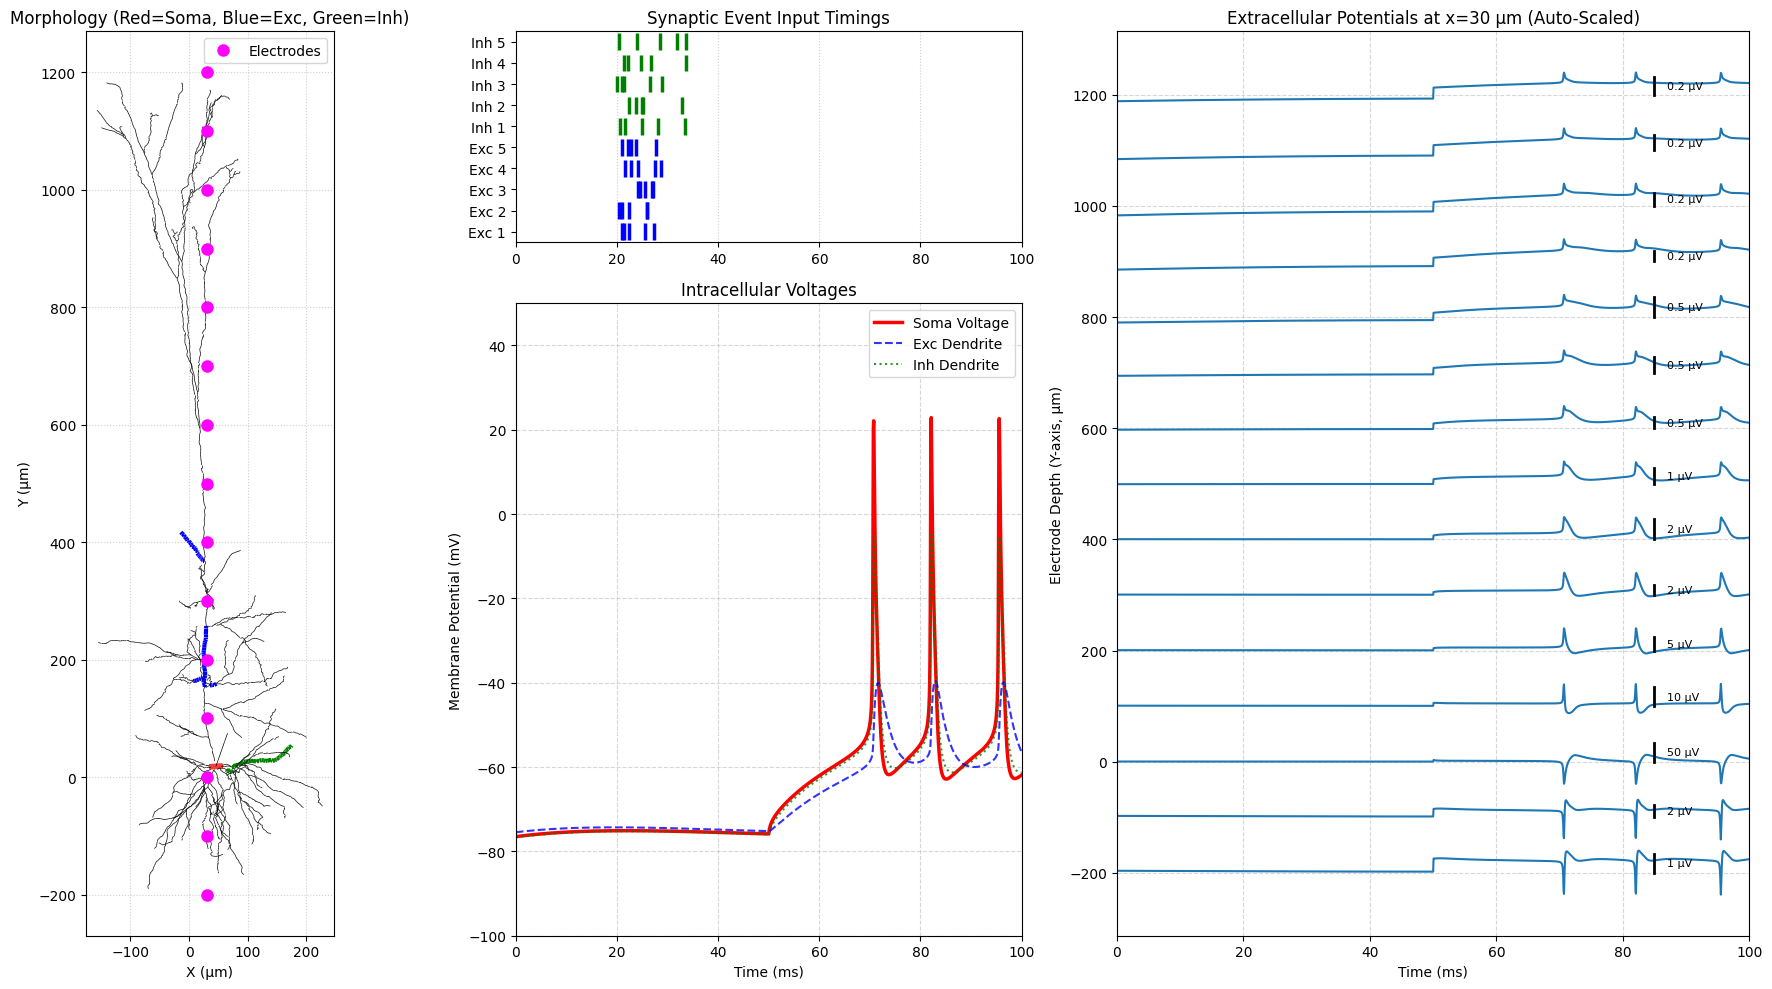

In [10]:
#@title Unified Interactive Simulation: Intracellular & Extracellular Dynamics { run: "auto" }
import LFPy
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import os
import neuron
import random

# --- Interactive Parameters ---
soma_current = 0.55 #@param {type:"slider", min:0.0, max:2.0, step:0.05}
exc_syn_weight = 0 #@param {type:"slider", min:0.0, max:0.1, step:0.005}
inh_syn_weight = 0 #@param {type:"slider", min:0.0, max:0.1, step:0.005}
electrode_x_pos = 30 #@param {type:"slider", min:10, max:200, step:10}
auto_scale_lfp = True #@param {type:"boolean"}

base_dir = '/content/bbp_l5pc'

# Ensure the model directory exists
if not os.path.exists(base_dir):
    print("Model directory not found. Re-downloading and compiling...")
    os.system('git clone https://github.com/ModelDBRepository/139653.git /content/bbp_l5pc')
    os.system('cd /content/bbp_l5pc && nrnivmodl mod')

# Load compiled mechanisms
dll_path = os.path.join(base_dir, 'x86_64/libnrnmech.so')
if os.path.exists(dll_path) and not hasattr(neuron.h, 'Ca_LVAst'):
    neuron.h.nrn_load_dll(dll_path)

# Get target dendrites from global scope if they exist, otherwise pick random apical
if 'target_dends' in globals():
    try:
        _target_dend_names = [sec.name() for sec in target_dends]
    except ReferenceError:
        _target_dend_names = []
else:
    _target_dend_names = []

def run_unified_sim(s_curr, e_weight, i_weight, x_pos):
    cell_parameters = {
        'morphology': os.path.join(base_dir, 'morphologies/cell1.asc'),
        'templatefile': [os.path.join(base_dir, 'models/L5PCbiophys3.hoc'), os.path.join(base_dir, 'models/L5PCtemplate.hoc')],
        'templatename': 'L5PCtemplate',
        'templateargs': os.path.join(base_dir, 'morphologies/cell1.asc'),
        'passive': False,
        'dt': 0.0625,
        'tstart': -20,
        'tstop': 100,
        'v_init': -80,
        'extracellular': True
    }

    current_dir = os.getcwd()
    os.chdir(base_dir)
    lfpy_cell = LFPy.TemplateCell(**cell_parameters)
    os.chdir(current_dir)

    # 1. Somatic Current Injection
    stimulus = LFPy.StimIntElectrode(
        lfpy_cell,
        idx=lfpy_cell.somaidx[0],
        record_current=True,
        pptype='IClamp',
        amp=s_curr,
        dur=100.0,
        delay=50.0
    )

    # 2. Excitatory Synaptic Inputs (Apical Dendrites)
    exc_synapses = []
    exc_spike_times_list = []
    exc_dend_indices = []

    if not _target_dend_names:
        apical_indices = [lfpy_cell.get_idx(sec.name())[0] for sec in lfpy_cell.allseclist if 'apic' in sec.name()]
        random.seed(42)
        exc_dend_indices = [random.choice(apical_indices) for _ in range(5)]
    else:
        for sec in lfpy_cell.allseclist:
            if sec.name() in _target_dend_names:
                exc_dend_indices.append(lfpy_cell.get_idx(sec.name())[0])

    for idx in exc_dend_indices:
        syn = LFPy.Synapse(
            lfpy_cell,
            idx=idx,
            syntype='ExpSyn',
            e=0, # Excitatory reversal potential
            tau=2.0,
            weight=e_weight,
            record_current=True
        )
        spikes = np.array([20.0 + random.uniform(0, 10) for _ in range(5)])
        syn.set_spike_times(spikes)
        exc_synapses.append(syn)
        exc_spike_times_list.append(spikes)

    # 3. Inhibitory Synaptic Inputs (Basal Dendrites)
    inh_synapses = []
    inh_spike_times_list = []
    basal_indices = [lfpy_cell.get_idx(sec.name())[0] for sec in lfpy_cell.allseclist if 'dend' in sec.name()]
    random.seed(123) # Different seed to spread them nicely
    inh_dend_indices = [random.choice(basal_indices) for _ in range(5)]

    for idx in inh_dend_indices:
        syn = LFPy.Synapse(
            lfpy_cell,
            idx=idx,
            syntype='ExpSyn',
            e=-80, # Inhibitory reversal potential
            tau=5.0,
            weight=i_weight,
            record_current=True
        )
        spikes = np.array([20.0 + random.uniform(0, 15) for _ in range(5)])
        syn.set_spike_times(spikes)
        inh_synapses.append(syn)
        inh_spike_times_list.append(spikes)

    # 4. Linear extracellular Multi-Electrode Array
    y_coords = np.linspace(-200, 1200, 15)
    x_coords = np.ones_like(y_coords) * x_pos
    z_coords = np.zeros_like(y_coords)

    probe = LFPy.RecExtElectrode(lfpy_cell, sigma=0.3, x=x_coords, y=y_coords, z=z_coords)

    # 5. Simulate
    print(f"Simulating: Soma={s_curr}nA, Exc_Weight={e_weight}, Inh_Weight={i_weight}, Electrodes at X={x_pos}µm...")
    lfpy_cell.simulate(rec_imem=True, rec_vmem=True, probes=[probe])

    LFP = probe.data * 1000
    tvec = lfpy_cell.tvec.copy()
    v_soma = lfpy_cell.vmem[lfpy_cell.somaidx[0], :].copy()

    v_exc_dends = [lfpy_cell.vmem[idx, :].copy() for idx in exc_dend_indices]
    v_inh_dends = [lfpy_cell.vmem[idx, :].copy() for idx in inh_dend_indices]

    # Morphology
    morph_lines = []
    morph_colors = []
    morph_lw = []
    for sec in lfpy_cell.allseclist:
        sec_idx = lfpy_cell.get_idx(sec.name())[0]
        is_soma = 'soma' in sec.name()
        is_exc = sec_idx in exc_dend_indices
        is_inh = sec_idx in inh_dend_indices

        if is_soma:
            c, lw = 'red', 4.0
        elif is_exc:
            c, lw = 'blue', 3.0
        elif is_inh:
            c, lw = 'green', 3.0
        else:
            c, lw = 'black', 0.5

        for i in range(sec.n3d() - 1):
            morph_lines.append([(sec.x3d(i), sec.y3d(i)), (sec.x3d(i+1), sec.y3d(i+1))])
            morph_colors.append(c)
            morph_lw.append(lw)

    return tvec, v_soma, v_exc_dends, v_inh_dends, LFP, x_coords, y_coords, morph_lines, morph_colors, morph_lw, exc_spike_times_list, inh_spike_times_list

tvec, v_soma, v_exc_dends, v_inh_dends, LFP, x_coords, y_coords, morph_lines, morph_colors, morph_lw, exc_spike_times_list, inh_spike_times_list = run_unified_sim(soma_current, exc_syn_weight, inh_syn_weight, electrode_x_pos)

# --- Plotting ---
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1.2, 1.5], height_ratios=[1, 3])

# Panel A: Synaptic Event Input Timings (Raster Plot)
ax_raster = fig.add_subplot(gs[0, 1])
total_spikes = len(exc_spike_times_list) + len(inh_spike_times_list)

# Plot Excitatory (Blue)
for idx, spikes in enumerate(exc_spike_times_list):
    ax_raster.vlines(spikes, idx + 0.6, idx + 1.4, colors='blue', linewidth=2.5)
# Plot Inhibitory (Green)
for idx, spikes in enumerate(inh_spike_times_list):
    offset_idx = idx + len(exc_spike_times_list)
    ax_raster.vlines(spikes, offset_idx + 0.6, offset_idx + 1.4, colors='green', linewidth=2.5)

ax_raster.set_yticks(range(1, total_spikes + 1))
ylabels = [f'Exc {i+1}' for i in range(len(exc_spike_times_list))] + [f'Inh {i+1}' for i in range(len(inh_spike_times_list))]
ax_raster.set_yticklabels(ylabels)
ax_raster.set_title('Synaptic Event Input Timings')
ax_raster.set_ylim(0.5, total_spikes + 0.5)
ax_raster.set_xlim(0, 100)
ax_raster.grid(True, axis='x', linestyle=':', alpha=0.6)

# Panel B: Intracellular Voltages (Soma & Dendrites)
ax_vmem = fig.add_subplot(gs[1, 1], sharex=ax_raster)
ax_vmem.plot(tvec, v_soma, label='Soma Voltage', color='red', linewidth=2.5)

# Plot just the first excitatory and inhibitory trace to avoid clutter
if v_exc_dends:
    ax_vmem.plot(tvec, v_exc_dends[0], label='Exc Dendrite', color='blue', linestyle='--', alpha=0.8)
if v_inh_dends:
    ax_vmem.plot(tvec, v_inh_dends[0], label='Inh Dendrite', color='green', linestyle=':', alpha=0.8)

ax_vmem.set_xlabel('Time (ms)')
ax_vmem.set_ylabel('Membrane Potential (mV)')
ax_vmem.set_title('Intracellular Voltages')
ax_vmem.legend(loc='best', fontsize=10)
ax_vmem.set_ylim(-100, 50)
ax_vmem.grid(True, linestyle='--', alpha=0.5)

# Panel C: Morphology & Electrodes
ax_morph = fig.add_subplot(gs[:, 0])
lc = LineCollection(morph_lines, colors=morph_colors, linewidths=morph_lw)
ax_morph.add_collection(lc)
ax_morph.plot(x_coords, y_coords, 'o', color='magenta', markersize=8, label='Electrodes')
ax_morph.set_aspect('equal')
ax_morph.set_xlabel('X (µm)')
ax_morph.set_ylabel('Y (µm)')
ax_morph.set_title('Morphology (Red=Soma, Blue=Exc, Green=Inh)')
ax_morph.autoscale_view()
ax_morph.legend()
ax_morph.grid(True, linestyle=':', alpha=0.6)

# Panel D: Extracellular LFP Traces
ax_lfp = fig.add_subplot(gs[:, 2])

if auto_scale_lfp:
    dy = y_coords[1] - y_coords[0] if len(y_coords) > 1 else 100
    for i in range(len(y_coords)):
        max_amp = np.max(np.abs(LFP[i, :]))
        if max_amp < 1e-6:
            max_amp = 1e-6

        # Scale each trace to fit within ~40% of the electrode spacing
        local_scale_factor = (dy * 0.4) / max_amp
        trace = LFP[i, :] * local_scale_factor
        ax_lfp.plot(tvec, trace + y_coords[i], color='#1f77b4', lw=1.5)

        # Dynamically calculate a nice, round scale bar value
        exponent = np.floor(np.log10(max_amp))
        base = max_amp / 10**exponent
        if base >= 5:
            nice_scale = 5 * 10**exponent
        elif base >= 2:
            nice_scale = 2 * 10**exponent
        else:
            nice_scale = 1 * 10**exponent

        bar_height = nice_scale * local_scale_factor
        ax_lfp.plot([85, 85], [y_coords[i], y_coords[i] + bar_height], 'k-', lw=2)

        nice_scale_str = f"{int(nice_scale)}" if nice_scale >= 1 and nice_scale.is_integer() else f"{nice_scale:.2g}"
        ax_lfp.text(87, y_coords[i] + bar_height/2, f'{nice_scale_str} µV', va='center', fontsize=8)

    ax_lfp.set_title(f'Extracellular Potentials at x={electrode_x_pos} µm (Auto-Scaled)')
else:
    scaling_factor = 2.0
    for i in range(len(y_coords)):
        trace = LFP[i, :] * scaling_factor
        ax_lfp.plot(tvec, trace + y_coords[i], color='#1f77b4', lw=1.5)

    scale_amp = 50 # uV
    ax_lfp.plot([85, 85], [y_coords[0], y_coords[0] + scale_amp * scaling_factor], 'k-', lw=3)
    ax_lfp.text(87, y_coords[0] + (scale_amp*scaling_factor)/2, f'{scale_amp} µV', va='center')
    ax_lfp.set_title(f'Extracellular Potentials (µV) at x={electrode_x_pos} µm (Fixed Scale)')

ax_lfp.set_xlabel('Time (ms)')
ax_lfp.set_ylabel('Electrode Depth (Y-axis, µm)')
ax_lfp.set_xlim(0, 100)
ax_lfp.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()
